# Reefugia: validating DHW against NOAA Coral Reef Watch
Compares reefugia's daily DHW for one region and year with NOAA CRW's 5 km DHW
product, using two measures.

- A **difference map** of peak DHW per pixel (reefugia − NOAA)
- **Correlations**, spatial (peak DHW across pixels) and in time (regional mean DHW per day)

reefugia's defaults follow NOAA as closely as Copernicus data allows. SST is C3S,
a record built for long-term stability, and the MMM uses NOAA's method (1985–2012
monthly means, trend evaluated at 1988.29). The SST products still differ, so a
small difference is expected. Section 5 runs reefugia's code on NOAA's own inputs
to separate the method from the inputs, and section 6 compares the two Copernicus
SST products (OSTIA's DHW runs well above NOAA's, see the README).

In [16]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from reefugia import constants, fetch, detect, validate, visualise, trend
from reefugia.constants import KELVIN_TO_CELSIUS

REGION = "red_sea"
YEAR   = 2023
START, END = f"{YEAR}-01-01", f"{YEAR}-12-31"
PLACE  = visualise.pretty_region(REGION)
PRODUCT = constants.SST_PRODUCT  # "c3s" (default) or "ostia"
print(f"SST product: {PRODUCT}, MMM baseline: {constants.DHW_MMM_BASELINE}")

SST product: c3s, MMM baseline: noaa


## 1. reefugia DHW (from the zarr cache if it exists)

In [17]:
sst = fetch.fetch_data(REGION, START, END)["analysed_sst"]
ocean_mask = ~sst.isel(time=0).isnull().compute()
dhw = detect.load_or_compute_dhw(sst, REGION, START, END)

INFO - 2026-11-11T10:03:56Z - Selected dataset version: "202506"
INFO - 2026-11-11T10:03:56Z - Selected dataset part: "default"


## 2. NOAA CRW DHW for the same year
Downloaded from NOAA's ERDDAP server once and cached in `data/`, so reruns don't
contact NOAA again.

In [18]:
crw = trend.load_or_fetch_crw_daily(REGION, START, END)
crw

<xarray.DataArray 'CRW_DHW' (time: 365, latitude: 361, longitude: 232)> Size: 245MB
dask.array<open_dataset-CRW_DHW, shape=(365, 361, 232), dtype=float64, chunksize=(46, 91, 58), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 3kB 2023-01-01T12:00:00 ... 2023-12-31T1...
  * latitude   (latitude) float32 1kB 30.02 29.98 29.92 ... 12.12 12.07 12.02
  * longitude  (longitude) float32 928B 31.98 32.03 32.08 ... 43.42 43.47 43.53
Attributes:
    colorBarMaximum:        16.0
    colorBarMinimum:        0.0
    coverage_content_type:  physicalMeasurement
    ioos_category:          Temperature
    long_name:              degree heating week
    units:                  Celsius weeks
    valid_max:              100.0
    valid_min:              0.0

## 3. Compare

In [19]:
result = validate.compare_dhw(dhw, crw, ocean_mask)

print(f"Pixels compared:        {result['n_pixels']} over {result['n_days']} days")
print(f"Spatial r (peak DHW):   {result['r_spatial']:.2f}")
print(f"Time r (regional mean): {result['r_timeseries']:.2f}")
print(f"Mean peak DHW:          {result['mean_peak']:.1f} (reefugia) vs {result['mean_peak_reference']:.1f} (NOAA)")
print(f"Mean bias:              {result['mean_bias']:+.1f} °C-weeks")
print(f"RMSE:                   {result['rmse']:.1f} °C-weeks")

Pixels compared:        16382 over 365 days
Spatial r (peak DHW):   0.68
Time r (regional mean): 0.99
Mean peak DHW:          11.9 (reefugia) vs 12.6 (NOAA)
Mean bias:              -0.7 °C-weeks
RMSE:                   2.8 °C-weeks


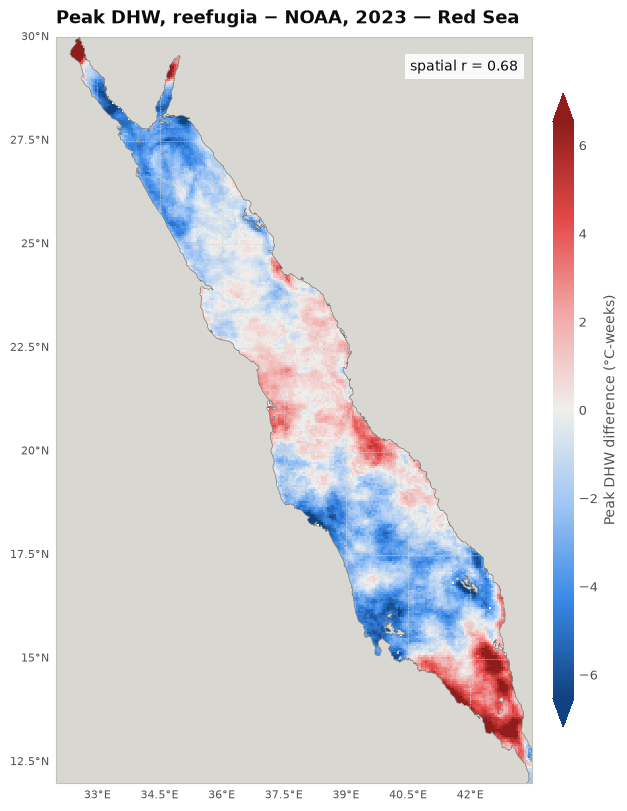

In [20]:
fig = visualise.plot_dhw_difference(
    result["diff"], result["r_spatial"],
    title=f"Peak DHW, reefugia − NOAA, {YEAR} — {PLACE}",
)
os.makedirs("../../outputs", exist_ok=True)
fig.savefig(f"../../outputs/dhw_vs_crw_{REGION}_{YEAR}.png", dpi=200, bbox_inches="tight")
plt.show()

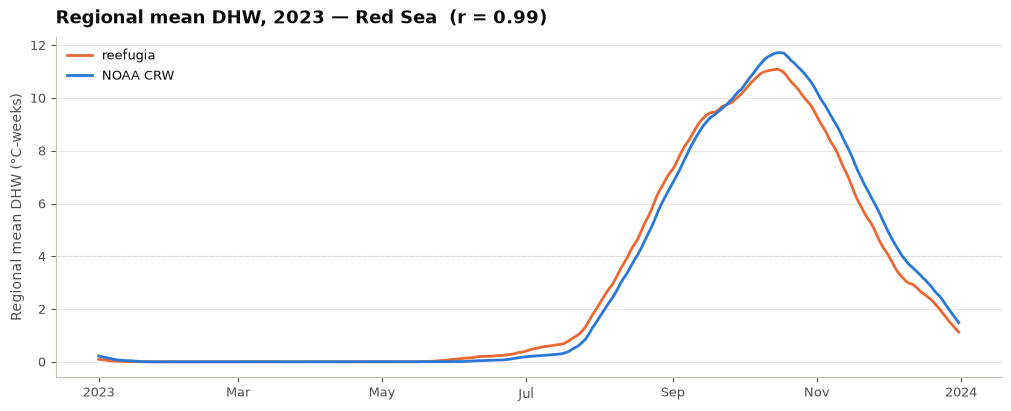

In [21]:
with plt.rc_context(visualise._STYLE):
    fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
    result["timeseries"].plot(ax=ax, color=visualise.ORANGE, linewidth=2, label="reefugia")
    result["timeseries_reference"].plot(ax=ax, color=visualise.BLUE, linewidth=2, label="NOAA CRW")
    ax.axhline(4, color="#b5b4ae", linewidth=0.8, linestyle="--", zorder=0)
    ax.set_xlabel("")
    ax.set_ylabel("Regional mean DHW (°C-weeks)")
    ax.yaxis.grid(True)
    ax.set_title(f"Regional mean DHW, {YEAR} — {PLACE}  (r = {result['r_timeseries']:.2f})")
    ax.legend(loc="upper left")
plt.show()

## 4. Where does the gap come from?
Two inputs can differ from NOAA's, the **MMM** and the **SST product**. They can be
separated, because NOAA's HotSpot is SST − MMM, so NOAA's MMM can be recovered from
its SST and HotSpot.

In [22]:
# from October, so section 5 has a full 12-week window on 1 January
lead_start = (pd.Timestamp(START) - pd.Timedelta(days=83)).strftime("%Y-%m-%d")
crw_sst_lead = trend.load_or_fetch_crw_daily(REGION, lead_start, END, "CRW_SST")
crw_sst = crw_sst_lead.sel(time=slice(START, None))
crw_hotspot = trend.load_or_fetch_crw_daily(REGION, START, END, "CRW_HOTSPOT")

mmm_noaa = validate.to_grid(validate.mmm_from_crw(crw_sst, crw_hotspot), dhw)  # °C
mmm_ours = detect.load_or_compute_climatology(REGION)["mmm"].compute() + KELVIN_TO_CELSIUS
mmm_diff = (mmm_ours - mmm_noaa).where(ocean_mask)

sst_ours = sst.mean(dim="time").compute() + KELVIN_TO_CELSIUS
sst_noaa = validate.to_grid(crw_sst.mean(dim="time"), dhw)
sst_diff = (sst_ours - sst_noaa).where(ocean_mask)

print(f"MMM, reefugia − NOAA:          mean {float(mmm_diff.mean()):+.2f} °C, "
      f"range {float(mmm_diff.quantile(0.05)):+.2f} to {float(mmm_diff.quantile(0.95)):+.2f} °C (5–95%)")
print(f"Annual mean SST, {PRODUCT.upper()} − CRW:  mean {float(sst_diff.mean()):+.2f} °C, "
      f"range {float(sst_diff.quantile(0.05)):+.2f} to {float(sst_diff.quantile(0.95)):+.2f} °C (5–95%)")

MMM, reefugia − NOAA:          mean +0.36 °C, range +0.11 to +0.73 °C (5–95%)
Annual mean SST, C3S − CRW:  mean +0.22 °C, range +0.06 to +0.38 °C (5–95%)


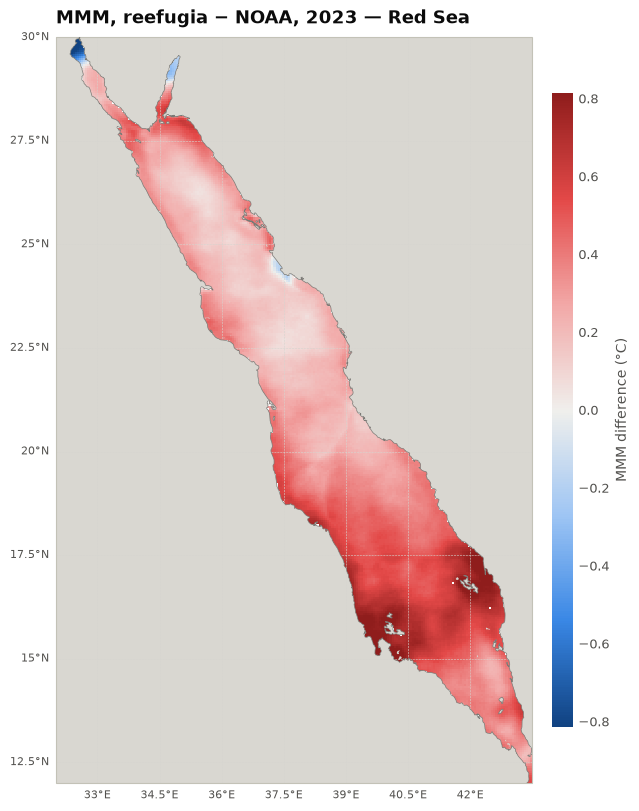

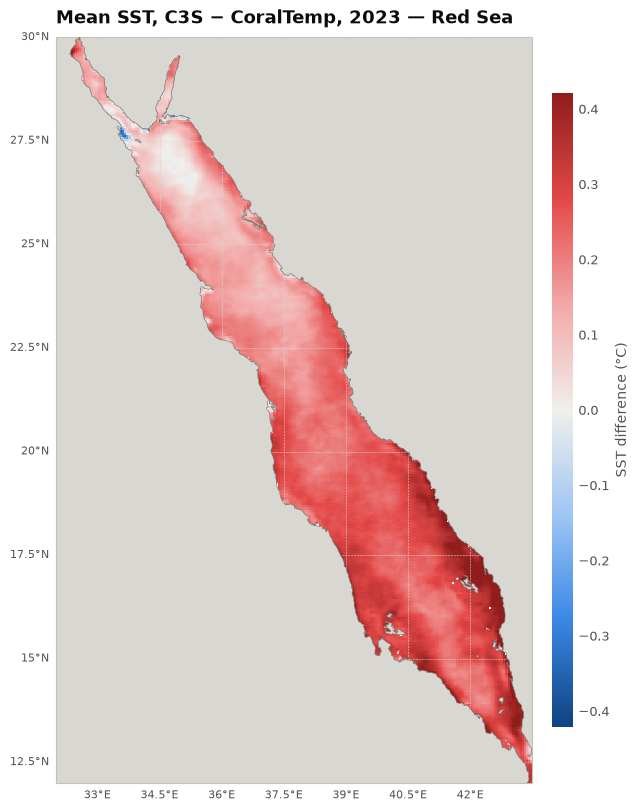

In [23]:
for diff, label, name in [(mmm_diff, "MMM difference (°C)", "MMM, reefugia − NOAA"),
                          (sst_diff, "SST difference (°C)", f"Mean SST, {PRODUCT.upper()} − CoralTemp")]:
    lim = float(abs(diff).quantile(0.98))
    visualise.plot_map(diff, label, title=f"{name}, {YEAR} — {PLACE}",
                       cmap=visualise.DIVERGING_CMAP, vmin=-lim, vmax=lim)
    plt.show()

### reefugia DHW with NOAA's MMM
Recomputing reefugia's DHW with NOAA's MMM leaves the SST product as the only
difference.

In [24]:
dhw_noaa_mmm = detect.compute_dhw(sst, REGION, mmm=mmm_noaa - KELVIN_TO_CELSIUS)
result_noaa_mmm = validate.compare_dhw(dhw_noaa_mmm, crw, ocean_mask)

keys = ["r_spatial", "r_timeseries", "mean_peak", "mean_peak_reference", "mean_bias", "rmse"]
pd.DataFrame({f"reefugia MMM + {PRODUCT.upper()} SST": [result[k] for k in keys],
              f"NOAA MMM + {PRODUCT.upper()} SST": [result_noaa_mmm[k] for k in keys]}, index=keys).round(2)

INFO - 2026-11-11T10:04:17Z - Selected dataset version: "202506"
INFO - 2026-11-11T10:04:17Z - Selected dataset part: "default"


,reefugia MMM + C3S SST,NOAA MMM + C3S SST
r_spatial,0.68,0.79
r_timeseries,0.99,0.99
mean_peak,11.87,16.91
mean_peak_reference,12.59,12.59
mean_bias,-0.73,4.31
rmse,2.79,5.35


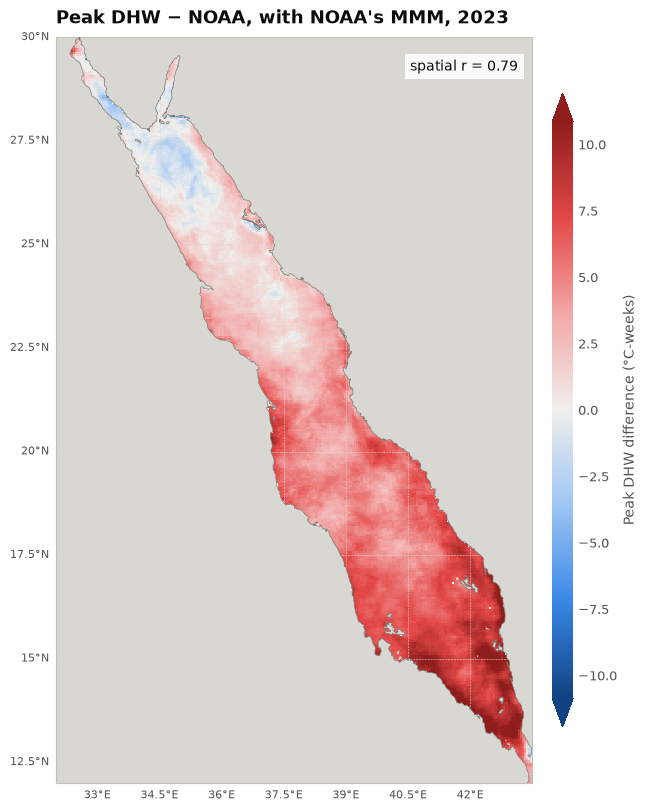

In [25]:
fig = visualise.plot_dhw_difference(
    result_noaa_mmm["diff"], result_noaa_mmm["r_spatial"],
    title=f"Peak DHW − NOAA, with NOAA's MMM, {YEAR}",
)
plt.show()

### Does the trend extrapolation cool the MMM?
NOAA's method reads its 1985–2012 trend off at 1988.29, about 10 years before the
middle of the period, so any difference in long-term trend between products gets
multiplied. Here the MMM is built instead from a plain average of the baseline years
themselves (1985–1990 and 1993), with no trend line. If it lands much closer to
NOAA's MMM, the extrapolation is what cools reefugia's MMM.

This downloads 1985–1993 SST for the region (not cached), so it takes a while.

In [26]:
BASELINE_YEARS = [1985, 1986, 1987, 1988, 1989, 1990, 1993]

sst_early = fetch.fetch_data(REGION, "1985-01-01", "1993-12-31")["analysed_sst"]
monthly = sst_early.resample(time="MS").mean()
monthly = monthly.sel(time=monthly.time.dt.year.isin(BASELINE_YEARS))
mmm_plain = (monthly.groupby("time.month").mean().max(dim="month").compute()
             + KELVIN_TO_CELSIUS)

def describe(diff):
    d = diff.where(ocean_mask)
    return f"mean {float(d.mean()):+.2f} °C, 5–95% {float(d.quantile(0.05)):+.2f} to {float(d.quantile(0.95)):+.2f}"

print(f"MMM with trend (reefugia) − NOAA:   {describe(mmm_ours - mmm_noaa)}")
print(f"MMM plain average − NOAA:           {describe(mmm_plain - mmm_noaa)}")
print(f"Trend minus plain average:          {describe(mmm_ours - mmm_plain)}")

INFO - 2026-11-11T10:04:55Z - Selected dataset version: "202506"
INFO - 2026-11-11T10:04:55Z - Selected dataset part: "default"


MMM with trend (reefugia) − NOAA:   mean +0.36 °C, 5–95% +0.11 to +0.73
MMM plain average − NOAA:           mean +0.29 °C, 5–95% -0.01 to +0.67
Trend minus plain average:          mean +0.07 °C, 5–95% -0.10 to +0.18


In [27]:
dhw_plain = detect.compute_dhw(sst, REGION, mmm=mmm_plain - KELVIN_TO_CELSIUS)
result_plain = validate.compare_dhw(dhw_plain, crw, ocean_mask)

pd.DataFrame({f"MMM with trend + {PRODUCT.upper()}": [result[k] for k in keys],
              f"MMM plain average + {PRODUCT.upper()}": [result_plain[k] for k in keys],
              f"NOAA MMM + {PRODUCT.upper()}": [result_noaa_mmm[k] for k in keys]},
             index=keys).round(2)

INFO - 2026-11-11T10:05:24Z - Selected dataset version: "202506"
INFO - 2026-11-11T10:05:24Z - Selected dataset part: "default"


,MMM with trend + C3S,MMM plain average + C3S,NOAA MMM + C3S
r_spatial,0.68,0.70,0.79
r_timeseries,0.99,1.00,0.99
mean_peak,11.87,12.92,16.91
mean_peak_reference,12.59,12.59,12.59
mean_bias,-0.73,0.33,4.31
rmse,2.79,2.86,5.35


## 5. Same inputs as NOAA
The final check of the method. reefugia's DHW code runs on NOAA's own SST
(CoralTemp) with NOAA's MMM, so every input matches NOAA's. Any remaining
difference comes from the calculation itself, and should be close to zero.

DHW needs the 12 weeks before each day, so this uses NOAA's SST from October of
the previous year, downloaded in section 4.

In [28]:
crw_sst_k = validate.to_grid(crw_sst_lead, dhw) - KELVIN_TO_CELSIUS

dhw_same_inputs = detect.compute_dhw(
    crw_sst_k, REGION, mmm=mmm_noaa - KELVIN_TO_CELSIUS, lead_in=False,
).sel(time=slice(START, None))
result_same = validate.compare_dhw(dhw_same_inputs, crw, ocean_mask)

pd.DataFrame({f"reefugia MMM + {PRODUCT.upper()} SST": [result[k] for k in keys],
              f"NOAA MMM + {PRODUCT.upper()} SST": [result_noaa_mmm[k] for k in keys],
              "NOAA MMM + NOAA SST": [result_same[k] for k in keys]}, index=keys).round(3)

,reefugia MMM + C3S SST,NOAA MMM + C3S SST,NOAA MMM + NOAA SST
r_spatial,0.676,0.795,1.000
r_timeseries,0.994,0.991,1.000
mean_peak,11.866,16.905,12.594
mean_peak_reference,12.594,12.594,12.594
mean_bias,-0.727,4.311,-0.000
rmse,2.789,5.354,0.003


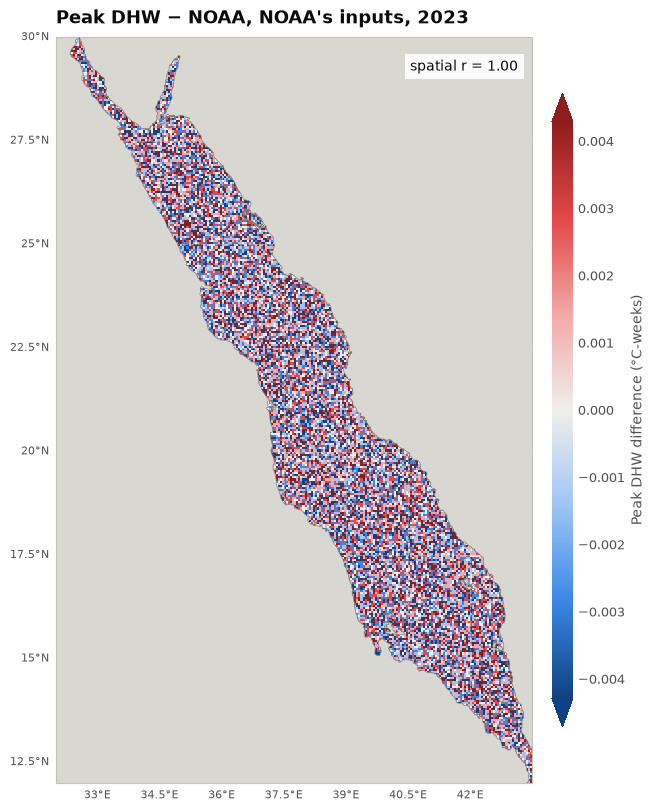

In [29]:
fig = visualise.plot_dhw_difference(
    result_same["diff"], result_same["r_spatial"],
    title=f"Peak DHW − NOAA, NOAA's inputs, {YEAR}",
)
plt.show()

## 6. OSTIA vs C3S
reefugia's default DHW from each Copernicus SST product, against NOAA. Each product
uses its own cached climatology, so the first run for a product downloads its
1985–2020 baseline, which is slow. Later runs load from the cache.

In [30]:
rows = {}
for product in ["ostia", "c3s"]:
    constants.SST_PRODUCT = product
    sst_p = fetch.fetch_data(REGION, START, END)["analysed_sst"]
    dhw_p = detect.load_or_compute_dhw(sst_p, REGION, START, END)
    r = validate.compare_dhw(dhw_p, crw, ocean_mask)
    rows[f"{product.upper()} (reefugia default)"] = [r[k] for k in keys]
constants.SST_PRODUCT = PRODUCT
rows["NOAA's own inputs"] = [result_same[k] for k in keys]

pd.DataFrame(rows, index=keys).round(3)

INFO - 2026-11-11T10:06:59Z - Selected dataset version: "202003"
INFO - 2026-11-11T10:06:59Z - Selected dataset part: "default"
INFO - 2026-11-11T10:07:04Z - Selected dataset version: "202506"
INFO - 2026-11-11T10:07:04Z - Selected dataset part: "default"


,OSTIA (reefugia default),C3S (reefugia default),NOAA's own inputs
r_spatial,0.669,0.676,1.000
r_timeseries,0.992,0.994,1.000
mean_peak,21.691,11.866,12.594
mean_peak_reference,12.594,12.594,12.594
mean_bias,9.097,-0.727,-0.000
rmse,9.978,2.789,0.003


## Notes
- The correlations test whether the method is right, meaning it puts heat stress
  in the same places at the same times as NOAA. The bias reflects the input
  differences described at the top.
- Large local differences near the coast are expected, since both SST products
  are least reliable there.